# ResNet-18 – Fashion-MNIST Classification

A Fashion-MNIST adathalmazhoz adaptált ResNet-18 architektúra implementációja,
baseline tanítása, optimalizálása és validációs értékelése.

A kísérletek a közös adatfelosztás, DL preprocessing pipeline és
training framework alkalmazásával készülnek.

- Random seed: 42
- Training samples: 50 000
- Validation samples: 10 000
- Test samples: 10 000
- Pretrained weights: None
- Training environment: Google Colab – GPU

## 1. Environment and Project Setup

In [6]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

print("Environment:", "Google Colab" if IN_COLAB else "Local")

Environment: Google Colab


In [7]:
import subprocess

REPO_URL = "https://github.com/aszenas/DLProject_FashionMNIST.git"
BRANCH = "feature/05-01-02-resnet18"

if IN_COLAB:
    PROJECT_ROOT = Path("/content/DLProject_FashionMNIST")

    if not PROJECT_ROOT.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--branch",
                BRANCH,
                REPO_URL,
                str(PROJECT_ROOT),
            ],
            check=True,
        )
else:
    PROJECT_ROOT = Path.cwd()

    if PROJECT_ROOT.name == "notebooks":
        PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /content/DLProject_FashionMNIST


In [8]:
import torch
import torchvision

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory (GiB):",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2,
        ),
    )

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Device: cuda
GPU: Tesla T4
GPU memory (GiB): 14.56


In [9]:
required_files = [
    "src/models/dl/resnet18.py",
    "src/preprocessing/dl.py",
    "src/training/dl.py",
    "src/preprocessing/dataset.py",
    "src/preprocessing/split.py",
    "data/splits.npz",
]

for filename in required_files:
    path = PROJECT_ROOT / filename
    assert path.is_file(), f"Missing file: {filename}"
    print(f"OK: {filename}")

OK: src/models/dl/resnet18.py
OK: src/preprocessing/dl.py
OK: src/training/dl.py
OK: src/preprocessing/dataset.py
OK: src/preprocessing/split.py
OK: data/splits.npz


### 1.1. Output Storage

A modell-checkpointokat és a kísérleti eredményeket a futtatási
környezet lokális tárhelyére mentjük. Colab használata esetén
az eredményeket minden kísérlet után manuálisan letöltjük.

In [10]:
OUTPUT_ROOT = PROJECT_ROOT

print("Output root:", OUTPUT_ROOT)

Output root: /content/DLProject_FashionMNIST


In [11]:
RESULTS_DIR = OUTPUT_ROOT / "results" / "experiments"
FIGURES_DIR = OUTPUT_ROOT / "results" / "figures" / "resnet18"
ARTIFACTS_DIR = OUTPUT_ROOT / "artifacts" / "resnet18"

for directory in [RESULTS_DIR, FIGURES_DIR, ARTIFACTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
    print(f"OK: {directory}")

OK: /content/DLProject_FashionMNIST/results/experiments
OK: /content/DLProject_FashionMNIST/results/figures/resnet18
OK: /content/DLProject_FashionMNIST/artifacts/resnet18


### 1.2. Dependencies and Environment

A közös DL preprocessing és training modulok importálása,
a random seed beállítása és a futtatási környezet rögzítése
a reprodukálhatóság érdekében.

In [12]:
import json
import os
import platform
from datetime import datetime, timezone
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
)
from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms

from src.models.dl.resnet18 import build_resnet18
from src.preprocessing.dataset import load_dataset
from src.preprocessing.dl import build_dataloaders
from src.preprocessing.split import load_split
from src.training.dl import (
    TrainingConfig,
    count_trainable_parameters,
    evaluate_model,
    fit_model,
    measure_inference_time,
    predict_model,
    set_random_seed,
)

SEED = 42
set_random_seed(SEED)

print("Imports successful.")
print("Random seed:", SEED)

Imports successful.
Random seed: 42


In [13]:
ENVIRONMENT = {
    "environment": "Google Colab" if IN_COLAB else "Local",
    "device": str(DEVICE),
    "gpu": (torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None),
    "gpu_memory_gib": (
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2,
        )
        if DEVICE.type == "cuda"
        else None
    ),
    "cuda_version": torch.version.cuda,
    "cudnn_version": torch.backends.cudnn.version(),
    "cpu": platform.processor() or platform.machine(),
    "cpu_logical_cores": os.cpu_count(),
    "os": platform.platform(),
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "sklearn_version": sklearn.__version__,
    "git_commit": subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        cwd=PROJECT_ROOT,
        text=True,
    ).strip(),
    "seed": SEED,
}

pd.DataFrame(
    ENVIRONMENT.items(),
    columns=["Property", "Value"],
)

,Property,Value
0,environment,Google Colab
1,device,cuda
2,gpu,Tesla T4
3,gpu_memory_gib,14.56
4,cuda_version,13.0
5,cudnn_version,92800
6,cpu,x86_64
7,cpu_logical_cores,2
8,os,Linux-6.6.159+-x86_64-with-glibc2.39
9,python_version,3.13.16


In [14]:
PALETTE = {
    "blue_1": "#DFE9EF",
    "blue_2": "#BDCEDB",
    "blue_3": "#8FA7BD",
    "blue_4": "#5E7891",
    "blue_5": "#32485F",
    "blue_6": "#1E3247",
    "blue_7": "#0F1B2A",
    "red_dark": "#7E3A42",
    "red_light": "#C47E86",
    "yellow_dark": "#E8BE0E",
    "yellow_light": "#F8E38B",
    "green_dark": "#7CA672",
    "green_light": "#CADBC6",
    "text": "#2F2F2F",
    "white": "#FFFFFF",
}

BLUE_CMAP = LinearSegmentedColormap.from_list(
    "project_blue",
    [
        PALETTE["blue_1"],
        PALETTE["blue_3"],
        PALETTE["blue_5"],
        PALETTE["blue_7"],
    ],
)

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 200,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "text.color": PALETTE["text"],
        "axes.labelcolor": PALETTE["text"],
    }
)

## 2. Dataset and Preprocessing

A közös Fashion-MNIST adatbetöltő és a korábban rögzített
stratifikált adatfelosztás alkalmazása.

A baseline konfiguráció standardizálás és augmentáció nélkül,
[0, 1] tartományba skálázott képeket használ.

In [15]:
train_dataset, test_dataset = load_dataset()
train_indices, val_indices = load_split()

CLASS_NAMES = train_dataset.classes

assert len(train_indices) == 50_000
assert len(val_indices) == 10_000
assert len(test_dataset) == 10_000
assert not set(train_indices).intersection(val_indices)

print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))
print("Test samples:", len(test_dataset))
print("Classes:", CLASS_NAMES)

100%|██████████| 26.4M/26.4M [00:02<00:00, 9.99MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 166kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.32MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 21.1MB/s]

Training samples: 50000
Validation samples: 10000
Test samples: 10000
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### 2.1. Baseline Configuration

Az RN-00 konfiguráció a research dokumentációban meghatározott
paramétereket követi. A tanítási beállítások megegyeznek
a Simple CNN baseline konfigurációjával.

In [16]:
BASELINE_CONFIG = {
    "dropout": 0.0,
    "num_classes": 10,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "weight_decay": 0.0,
    "scheduler": None,
    "epochs": 10,
    "batch_size": 64,
    "loss": "CrossEntropyLoss",
    "standardize": False,
    "train_augmentation": None,
    "pretrained_weights": None,
    "seed": SEED,
}

pd.DataFrame(
    BASELINE_CONFIG.items(),
    columns=["Parameter", "Value"],
)

,Parameter,Value
0,dropout,0.0
1,num_classes,10
2,optimizer,Adam
3,learning_rate,0.001
4,weight_decay,0.0
5,scheduler,None
6,epochs,10
7,batch_size,64
8,loss,CrossEntropyLoss
9,standardize,False


In [17]:
baseline_loaders = build_dataloaders(
    train_dataset,
    test_dataset,
    train_indices,
    val_indices,
    batch_size=BASELINE_CONFIG["batch_size"],
    seed=BASELINE_CONFIG["seed"],
    standardize=BASELINE_CONFIG["standardize"],
    train_augmentation=None,
)

inputs, targets = next(iter(baseline_loaders["val"]))

assert inputs.shape == (64, 1, 28, 28)
assert targets.shape == (64,)
assert inputs.dtype == torch.float32
assert targets.dtype == torch.int64
assert inputs.min().item() >= 0.0
assert inputs.max().item() <= 1.0

print("Input shape:", inputs.shape)
print("Target shape:", targets.shape)
print("Input dtype:", inputs.dtype)
print("Target dtype:", targets.dtype)
print("Pixel range:", inputs.min().item(), inputs.max().item())

for split, loader in baseline_loaders.items():
    print(f"{split}: {len(loader.dataset)} samples, {len(loader)} batches")

Input shape: torch.Size([64, 1, 28, 28])
Target shape: torch.Size([64])
Input dtype: torch.float32
Target dtype: torch.int64
Pixel range: 0.0 1.0
train: 50000 samples, 782 batches
val: 10000 samples, 157 batches
test: 10000 samples, 157 batches


## 3. Model Architecture

A Torchvision ResNet-18 architektúrájának adaptálása a Fashion-MNIST
egycsatornás, 28×28 pixeles képeihez.

- 3×3-as kezdeti konvolúció, stride=1.
- Kezdeti max pooling elhagyása.
- Változatlan [2, 2, 2, 2] reziduális blokkstruktúra.
- 10 kimeneti logit.
- Előtanított súlyok nélkül.

A részletes architekturális indoklás a 4.1.2 research
dokumentációban található.

In [18]:
set_random_seed(SEED)

baseline_model = build_resnet18(
    dropout=BASELINE_CONFIG["dropout"],
    num_classes=BASELINE_CONFIG["num_classes"],
).to(DEVICE)

parameter_count = count_trainable_parameters(baseline_model)

assert parameter_count == 11_172_810

print("Model:", type(baseline_model).__name__)
print("Device:", next(baseline_model.parameters()).device)
print(f"Trainable parameters: {parameter_count:,}")

Model: ResNet
Device: cuda:0
Trainable parameters: 11,172,810


In [19]:
baseline_model.eval()

architecture_rows = []
x = inputs.to(DEVICE)

with torch.no_grad():
    architecture_rows.append(
        {
            "Layer": "Input",
            "Output shape": tuple(x.shape[1:]),
        }
    )

    for name in [
        "conv1",
        "bn1",
        "relu",
        "maxpool",
        "layer1",
        "layer2",
        "layer3",
        "layer4",
        "avgpool",
    ]:
        x = getattr(baseline_model, name)(x)

        architecture_rows.append(
            {
                "Layer": name,
                "Output shape": tuple(x.shape[1:]),
            }
        )

    x = torch.flatten(x, 1)
    logits = baseline_model.fc(x)

    architecture_rows.append(
        {
            "Layer": "fc",
            "Output shape": tuple(logits.shape[1:]),
        }
    )

    direct_logits = baseline_model(inputs.to(DEVICE))

assert logits.shape == (64, 10)
assert torch.isfinite(logits).all().item()
assert torch.allclose(logits, direct_logits)

pd.DataFrame(architecture_rows)

,Layer,Output shape
0,Input,"(1, 28, 28)"
1,conv1,"(64, 28, 28)"
2,bn1,"(64, 28, 28)"
3,relu,"(64, 28, 28)"
4,maxpool,"(64, 28, 28)"
5,layer1,"(64, 28, 28)"
6,layer2,"(128, 14, 14)"
7,layer3,"(256, 7, 7)"
8,layer4,"(512, 4, 4)"
9,avgpool,"(512, 1, 1)"


In [20]:
criterion = nn.CrossEntropyLoss()

with torch.no_grad():
    loss = criterion(logits, targets.to(DEVICE))

assert torch.isfinite(loss).item()

print("Logits shape:", logits.shape)
print("Initial loss:", round(loss.item(), 4))
print("Model validation successful.")

Logits shape: torch.Size([64, 10])
Initial loss: 2.296
Model validation successful.


## 4. Experiment Framework

Újrafelhasználható kísérletfuttatási és eredménynaplózási
infrastruktúra kialakítása a közös DL training framework alapján.

Minden kísérlet önálló konfigurációval, rögzített random seeddel,
epochonkénti metrikákkal és mentett model-checkpointtal rendelkezik.

### 4.1. Result Storage

In [21]:
RESULTS_PATH = RESULTS_DIR / "resnet18_experiments.csv"
EPOCH_HISTORY_PATH = RESULTS_DIR / "resnet18_epoch_history.csv"
FINAL_METRICS_PATH = RESULTS_DIR / "resnet18_final_metrics.csv"
CLASSIFICATION_REPORT_PATH = RESULTS_DIR / "resnet18_classification_report.csv"

In [22]:
def save_run_rows(path, run_id, rows):
    """Save experiment rows without duplicating an existing run."""
    new_rows = pd.DataFrame(rows)

    if path.exists():
        existing = pd.read_csv(path)

        existing = existing[existing["run_id"] != run_id]

        if not existing.empty:
            new_rows = pd.concat(
                [existing, new_rows],
                ignore_index=True,
            )

    sort_columns = ["run_id"]

    if "epoch" in new_rows.columns:
        sort_columns.append("epoch")

    new_rows = new_rows.sort_values(sort_columns)
    new_rows.to_csv(path, index=False)

### 4.2. Preprocessing Configuration

A kísérletek preprocessing beállításait a közös DL pipeline
segítségével alkalmazzuk.

A training metrikák számításához külön, augmentáció nélküli
DataLoadert használunk, hogy az értékelési körülmények
összehasonlíthatók legyenek.

In [23]:
def build_experiment_loaders(config):
    """Build training and evaluation loaders for one experiment."""
    augmentation = config["train_augmentation"]

    if augmentation is None:
        train_augmentation = None

    elif augmentation == "RandomAffine":
        train_augmentation = transforms.RandomAffine(
            degrees=8,
            translate=(0.05, 0.05),
        )

    else:
        raise ValueError(f"Unsupported augmentation: {augmentation}")

    loaders = build_dataloaders(
        train_dataset,
        test_dataset,
        train_indices,
        val_indices,
        batch_size=config["batch_size"],
        seed=config["seed"],
        standardize=config["standardize"],
        train_augmentation=train_augmentation,
    )

    # Reuse the validation transform on the training samples.
    train_dataset_eval = type(loaders["train"].dataset)(
        train_dataset,
        train_indices,
        loaders["val"].dataset.transform,
    )

    loaders["train_eval"] = DataLoader(
        train_dataset_eval,
        batch_size=config["batch_size"],
        shuffle=False,
    )

    return loaders

In [24]:
experiment_loaders = build_experiment_loaders(BASELINE_CONFIG)

assert len(experiment_loaders["train_eval"].dataset) == 50_000

assert (
    experiment_loaders["train"].dataset.indices
    == experiment_loaders["train_eval"].dataset.indices.tolist()
)

for split, loader in experiment_loaders.items():
    print(f"{split}: {len(loader.dataset)} samples, {len(loader)} batches")

train: 50000 samples, 782 batches
val: 10000 samples, 157 batches
test: 10000 samples, 157 batches
train_eval: 50000 samples, 782 batches


### 4.3. Checkpoint Storage and Backup

Minden kísérlethez elmentjük a legjobb validációs teljesítményt
elérő modellállapotot, a modell- és preprocessing konfigurációt,
valamint a legjobb epoch sorszámát.

Colab használata esetén az eredményeket ZIP-formátumban
manuálisan letöltjük.

In [25]:
def save_checkpoint(run_id, config, best_state, best_epoch, loaders):
    """Save model weights and experiment configuration."""
    run_dir = ARTIFACTS_DIR / run_id
    run_dir.mkdir(parents=True, exist_ok=True)

    normalization = None

    if config["standardize"]:
        for transform in loaders["val"].dataset.transform.transforms:
            if isinstance(transform, transforms.Normalize):
                normalization = {
                    "mean": list(transform.mean),
                    "std": list(transform.std),
                }
                break

        assert normalization is not None

    checkpoint = {
        "run_id": run_id,
        "model_name": "ResNet-18",
        "config": config.copy(),
        "best_epoch": best_epoch,
        "normalization": normalization,
        "state_dict": {name: tensor.detach().cpu() for name, tensor in best_state.items()},
    }

    checkpoint_path = run_dir / "model.pt"
    torch.save(checkpoint, checkpoint_path)

    with open(run_dir / "config.json", "w", encoding="utf-8") as file:
        json.dump(config, file, indent=4)

    return {
        "checkpoint_path": str(checkpoint_path),
        "model_size_bytes": checkpoint_path.stat().st_size,
        "model_size_mib": checkpoint_path.stat().st_size / 1024**2,
    }

In [26]:
from zipfile import ZIP_DEFLATED, ZipFile


def download_experiment_backup(run_id):
    """Export a checkpoint and current ResNet-18 results."""
    run_dir = ARTIFACTS_DIR / run_id

    if not (run_dir / "model.pt").is_file():
        raise FileNotFoundError(f"Missing checkpoint: {run_id}")

    zip_path = OUTPUT_ROOT / f"resnet18_backup_{run_id}.zip"

    files_to_export = [
        *run_dir.rglob("*"),
        *RESULTS_DIR.glob("resnet18_*.csv"),
        *FIGURES_DIR.rglob("*.png"),
    ]

    with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as archive:
        for path in files_to_export:
            if path.is_file():
                archive.write(
                    path,
                    arcname=path.relative_to(OUTPUT_ROOT),
                )

    print(f"Backup created: {zip_path.name}")
    print(f"Backup size: {zip_path.stat().st_size / 1024**2:.2f} MiB")

    if IN_COLAB:
        from google.colab import files

        files.download(str(zip_path))

    return zip_path

### 4.4. Experiment Runner

A kísérletfuttató függvény egységesen kezeli az adat-előfeldolgozást,
a modell inicializálását, a tanítást, a validációs alapú checkpoint
kiválasztását, az inferenciamérést és az eredmények mentését.

In [27]:
def run_experiment(run_id, config, description=""):
    """Train and evaluate a ResNet-18 experiment."""
    config = config.copy()

    set_random_seed(config["seed"])

    print(f"\nStarting experiment: {run_id}")
    print(f"Description: {description}")

    # 1. Preprocessing
    preprocessing_start = perf_counter()

    loaders = build_experiment_loaders(config)

    preprocessing_time = perf_counter() - preprocessing_start

    # 2. Model initialization
    model = build_resnet18(
        dropout=config["dropout"],
        num_classes=config["num_classes"],
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss()

    training_config = TrainingConfig(
        epochs=config["epochs"],
        learning_rate=config["learning_rate"],
        weight_decay=config["weight_decay"],
        scheduler=config["scheduler"],
    )

    # 3. Training and best checkpoint selection
    history, best_epoch, best_state, training_time = fit_model(
        model=model,
        train_loader=loaders["train"],
        train_eval_loader=loaders["train_eval"],
        val_loader=loaders["val"],
        criterion=criterion,
        config=training_config,
        device=DEVICE,
    )

    best_metrics = next(row for row in history if row["epoch"] == best_epoch)

    # 4. Inference benchmark
    full_inference_time, forward_inference_time = measure_inference_time(
        model=model,
        loader=loaders["val"],
        device=DEVICE,
        repeats=5,
    )

    # 5. Checkpoint storage
    artifact_info = save_checkpoint(
        run_id,
        config,
        best_state,
        best_epoch,
        loaders,
    )

    # 6. Experiment result
    result = {
        "run_id": run_id,
        "model_name": "ResNet-18",
        "description": description,
        "timestamp": datetime.now(timezone.utc).isoformat(),
        **config,
        "best_epoch": best_epoch,
        "n_train_samples": len(loaders["train"].dataset),
        "n_val_samples": len(loaders["val"].dataset),
        "train_loss": best_metrics["train_loss"],
        "train_accuracy": best_metrics["train_accuracy"],
        "train_macro_f1": best_metrics["train_macro_f1"],
        "val_loss": best_metrics["val_loss"],
        "val_accuracy": best_metrics["val_accuracy"],
        "val_macro_f1": best_metrics["val_macro_f1"],
        "accuracy_gap": (best_metrics["train_accuracy"] - best_metrics["val_accuracy"]),
        "preprocessing_time_s": preprocessing_time,
        "training_time_s": training_time,
        "inference_time_s": full_inference_time,
        "forward_inference_time_s": forward_inference_time,
        "inference_time_per_sample_ms": (full_inference_time / len(loaders["val"].dataset) * 1000),
        "parameter_count": count_trainable_parameters(model),
        **artifact_info,
        **ENVIRONMENT,
        "seed": config["seed"],
    }

    # 7. CSV logging
    save_run_rows(
        RESULTS_PATH,
        run_id,
        [result],
    )

    history_rows = [{"run_id": run_id, **row} for row in history]

    save_run_rows(
        EPOCH_HISTORY_PATH,
        run_id,
        history_rows,
    )

    print(f"\nExperiment completed: {run_id}")
    print(f"Best epoch: {best_epoch}")
    print(f"Validation accuracy: {result['val_accuracy']:.4f}")
    print(f"Validation macro F1: {result['val_macro_f1']:.4f}")
    print(f"Training time: {training_time:.2f} s")
    print(f"Checkpoint size: {result['model_size_mib']:.2f} MiB")

    return {
        "model": model,
        "loaders": loaders,
        "history": pd.DataFrame(history_rows),
        "result": result,
        "config": config,
    }

## 5. Baseline Experiment

### 5.1. RN-00 – Baseline

A research dokumentációban meghatározott baseline konfiguráció
tanítása előtanított súlyok, standardizálás, augmentáció és
regularizáció nélkül.

- Adam optimizer, learning rate=0.001
- Batch size=64
- Epochs=10
- Random seed=42

A kísérlet referenciaként szolgál a további optimalizálásokhoz.

In [23]:
baseline = run_experiment(
    run_id="RN-00",
    config=BASELINE_CONFIG,
    description="Baseline",
)


Starting experiment: RN-00
Description: Baseline
Epoch 01/10: train_loss=0.2669, train_acc=0.9017, val_loss=0.2753, val_acc=0.9010, val_macro_f1=0.9011, duration=65.22s
Epoch 02/10: train_loss=0.1880, train_acc=0.9304, val_loss=0.2151, val_acc=0.9195, val_macro_f1=0.9187, duration=64.32s
Epoch 03/10: train_loss=0.1830, train_acc=0.9320, val_loss=0.2298, val_acc=0.9168, val_macro_f1=0.9181, duration=64.15s
Epoch 04/10: train_loss=0.1570, train_acc=0.9420, val_loss=0.2326, val_acc=0.9189, val_macro_f1=0.9187, duration=64.54s
Epoch 05/10: train_loss=0.1112, train_acc=0.9607, val_loss=0.1881, val_acc=0.9333, val_macro_f1=0.9337, duration=64.01s
Epoch 06/10: train_loss=0.0881, train_acc=0.9683, val_loss=0.1972, val_acc=0.9323, val_macro_f1=0.9322, duration=64.28s
Epoch 07/10: train_loss=0.0703, train_acc=0.9749, val_loss=0.2180, val_acc=0.9319, val_macro_f1=0.9325, duration=64.38s
Epoch 08/10: train_loss=0.0575, train_acc=0.9810, val_loss=0.2229, val_acc=0.9311, val_macro_f1=0.9312, durati

In [24]:
baseline_result = baseline["result"]

pd.DataFrame([baseline_result])[
    [
        "run_id",
        "best_epoch",
        "train_accuracy",
        "val_accuracy",
        "train_macro_f1",
        "val_macro_f1",
        "train_loss",
        "val_loss",
        "accuracy_gap",
        "preprocessing_time_s",
        "training_time_s",
        "inference_time_s",
        "forward_inference_time_s",
        "parameter_count",
        "model_size_mib",
    ]
].T

,0
run_id,RN-00
best_epoch,9
train_accuracy,0.98802
val_accuracy,0.9339
train_macro_f1,0.988006
val_macro_f1,0.933851
train_loss,0.036837
val_loss,0.23267
accuracy_gap,0.05412
preprocessing_time_s,0.014301


In [25]:
download_experiment_backup("RN-00")

Backup created: resnet18_backup_RN-00.zip
Backup size: 39.56 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PosixPath('/content/DLProject_FashionMNIST/resnet18_backup_RN-00.zip')

### Baseline Observations

A modell a 9. epochban érte el a legjobb validációs teljesítményét
(accuracy: 93,39%, macro F1: 93,39%), meghaladva a Simple CNN
optimalizált konfigurációjának eredményét.

Az 5. epoch után a training loss tovább csökken, miközben a
validation loss növekszik és a validációs pontosság stagnál,
ami túlilleszkedésre utal, és indokolja a regularizációs
technikák vizsgálatát.

## 6. Hyperparameter Optimization

Az egyedi kísérletek során egyszerre egy paramétert módosítunk
a baseline konfigurációhoz képest. A modellválasztás kizárólag
a validációs eredmények alapján történik.

### 6.1. RN-01 – Dropout

Dropout=0.3 alkalmazása a Global Average Pooling után,
az osztályozóréteg előtt, a túlilleszkedés mérséklése érdekében.

In [26]:
rn01_config = {
    **BASELINE_CONFIG,
    "dropout": 0.3,
}

rn01 = run_experiment(
    run_id="RN-01",
    config=rn01_config,
    description="Dropout=0.3",
)


Starting experiment: RN-01
Description: Dropout=0.3
Epoch 01/10: train_loss=0.2650, train_acc=0.9046, val_loss=0.2761, val_acc=0.9016, val_macro_f1=0.9015, duration=65.84s
Epoch 02/10: train_loss=0.1839, train_acc=0.9326, val_loss=0.2129, val_acc=0.9223, val_macro_f1=0.9221, duration=64.73s
Epoch 03/10: train_loss=0.1879, train_acc=0.9290, val_loss=0.2400, val_acc=0.9136, val_macro_f1=0.9158, duration=64.23s
Epoch 04/10: train_loss=0.1503, train_acc=0.9450, val_loss=0.2146, val_acc=0.9245, val_macro_f1=0.9247, duration=64.61s
Epoch 05/10: train_loss=0.1125, train_acc=0.9604, val_loss=0.1799, val_acc=0.9346, val_macro_f1=0.9351, duration=64.99s
Epoch 06/10: train_loss=0.0859, train_acc=0.9695, val_loss=0.1853, val_acc=0.9330, val_macro_f1=0.9329, duration=65.83s
Epoch 07/10: train_loss=0.0752, train_acc=0.9727, val_loss=0.2152, val_acc=0.9318, val_macro_f1=0.9323, duration=65.89s
Epoch 08/10: train_loss=0.0566, train_acc=0.9813, val_loss=0.2223, val_acc=0.9311, val_macro_f1=0.9315, dur

In [36]:
download_experiment_backup("RN-01")

Backup created: resnet18_backup_RN-01.zip
Backup size: 39.57 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PosixPath('/content/DLProject_FashionMNIST/resnet18_backup_RN-01.zip')

**Observations**

A dropout alkalmazásával a validációs pontosság 93,46%-ra nőtt,
ami 0,07 százalékpontos javulás a baseline-hoz képest.
A train-validation gap 5,41-ről 2,58 százalékpontra, a validation
loss pedig 0,2327-ről 0,1799-re csökkent, ami a túlilleszkedés
mérséklődésére utal.

### 6.2. RN-02 – Learning Rate

A learning rate csökkentése 0.001-ről 0.0003-ra
a stabilabb optimalizáció és konvergencia vizsgálatához.

In [28]:
rn02_config = {
    **BASELINE_CONFIG,
    "learning_rate": 0.0003,
}

rn02 = run_experiment(
    run_id="RN-02",
    config=rn02_config,
    description="Learning rate=0.0003",
)


Starting experiment: RN-02
Description: Learning rate=0.0003
Epoch 01/10: train_loss=0.2442, train_acc=0.9149, val_loss=0.2675, val_acc=0.9041, val_macro_f1=0.9043, duration=65.03s
Epoch 02/10: train_loss=0.1647, train_acc=0.9416, val_loss=0.2140, val_acc=0.9243, val_macro_f1=0.9241, duration=63.86s
Epoch 03/10: train_loss=0.1361, train_acc=0.9510, val_loss=0.2153, val_acc=0.9200, val_macro_f1=0.9207, duration=64.86s
Epoch 04/10: train_loss=0.1002, train_acc=0.9637, val_loss=0.2228, val_acc=0.9215, val_macro_f1=0.9217, duration=64.26s
Epoch 05/10: train_loss=0.0830, train_acc=0.9715, val_loss=0.2254, val_acc=0.9229, val_macro_f1=0.9235, duration=63.87s
Epoch 06/10: train_loss=0.0629, train_acc=0.9773, val_loss=0.2688, val_acc=0.9203, val_macro_f1=0.9192, duration=64.02s
Epoch 07/10: train_loss=0.0567, train_acc=0.9779, val_loss=0.2699, val_acc=0.9183, val_macro_f1=0.9193, duration=64.04s
Epoch 08/10: train_loss=0.0330, train_acc=0.9888, val_loss=0.2605, val_acc=0.9259, val_macro_f1=0.

In [29]:
download_experiment_backup("RN-02")

Backup created: resnet18_backup_RN-02.zip
Backup size: 39.63 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PosixPath('/content/DLProject_FashionMNIST/resnet18_backup_RN-02.zip')

**Observations**

Az alacsonyabb learning rate 92,59%-os validációs pontosságot
eredményezett, ami 0,80 százalékponttal elmarad a baseline-tól.
A magasabb train-validation gap és validation loss alapján
ez a konfiguráció nem javította a modell általánosítási képességét.

### 6.3. RN-03 – Standardization

A bemeneti képek standardizálása a training halmazon
meghatározott átlag és szórás alapján, az optimalizációra
és a prediktív teljesítményre gyakorolt hatás vizsgálatához.

In [30]:
rn03_config = {
    **BASELINE_CONFIG,
    "standardize": True,
}

rn03 = run_experiment(
    run_id="RN-03",
    config=rn03_config,
    description="Input standardization",
)


Starting experiment: RN-03
Description: Input standardization
Epoch 01/10: train_loss=0.2666, train_acc=0.9043, val_loss=0.2764, val_acc=0.9010, val_macro_f1=0.9010, duration=72.06s
Epoch 02/10: train_loss=0.1852, train_acc=0.9318, val_loss=0.2212, val_acc=0.9192, val_macro_f1=0.9186, duration=71.10s
Epoch 03/10: train_loss=0.1894, train_acc=0.9282, val_loss=0.2481, val_acc=0.9106, val_macro_f1=0.9124, duration=71.38s
Epoch 04/10: train_loss=0.1471, train_acc=0.9459, val_loss=0.2205, val_acc=0.9226, val_macro_f1=0.9227, duration=71.35s
Epoch 05/10: train_loss=0.1173, train_acc=0.9599, val_loss=0.1959, val_acc=0.9292, val_macro_f1=0.9297, duration=71.30s
Epoch 06/10: train_loss=0.0804, train_acc=0.9713, val_loss=0.1976, val_acc=0.9320, val_macro_f1=0.9319, duration=71.57s
Epoch 07/10: train_loss=0.0779, train_acc=0.9712, val_loss=0.2261, val_acc=0.9285, val_macro_f1=0.9288, duration=71.24s
Epoch 08/10: train_loss=0.0486, train_acc=0.9832, val_loss=0.2269, val_acc=0.9304, val_macro_f1=0

In [31]:
download_experiment_backup("RN-03")

Backup created: resnet18_backup_RN-03.zip
Backup size: 39.56 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PosixPath('/content/DLProject_FashionMNIST/resnet18_backup_RN-03.zip')

**Observations**

A standardizálás mellett a modell 93,20%-os validációs
pontosságot ért el. Bár a validation loss és a train-validation
gap csökkent, a standardizálás a Simple CNN-nel ellentétben
nem eredményezett pontosságjavulást a ResNet-18 esetében.

### 6.4. RN-04 – Data Augmentation

RandomAffine transzformáció alkalmazása kizárólag a training
halmazon, maximum 8 fokos forgatással és 5%-os eltolással,
a modell általánosítási képességének javítása érdekében.

In [32]:
rn04_config = {
    **BASELINE_CONFIG,
    "train_augmentation": "RandomAffine",
}

rn04 = run_experiment(
    run_id="RN-04",
    config=rn04_config,
    description="RandomAffine augmentation",
)


Starting experiment: RN-04
Description: RandomAffine augmentation
Epoch 01/10: train_loss=0.3124, train_acc=0.8852, val_loss=0.3029, val_acc=0.8895, val_macro_f1=0.8861, duration=67.03s
Epoch 02/10: train_loss=0.2519, train_acc=0.9075, val_loss=0.2563, val_acc=0.9069, val_macro_f1=0.9050, duration=67.20s
Epoch 03/10: train_loss=0.2292, train_acc=0.9138, val_loss=0.2391, val_acc=0.9105, val_macro_f1=0.9128, duration=67.17s
Epoch 04/10: train_loss=0.2209, train_acc=0.9183, val_loss=0.2354, val_acc=0.9136, val_macro_f1=0.9130, duration=66.80s
Epoch 05/10: train_loss=0.1906, train_acc=0.9270, val_loss=0.2118, val_acc=0.9211, val_macro_f1=0.9219, duration=66.92s
Epoch 06/10: train_loss=0.1634, train_acc=0.9397, val_loss=0.1905, val_acc=0.9294, val_macro_f1=0.9296, duration=67.35s
Epoch 07/10: train_loss=0.1969, train_acc=0.9246, val_loss=0.2267, val_acc=0.9190, val_macro_f1=0.9192, duration=67.04s
Epoch 08/10: train_loss=0.1649, train_acc=0.9390, val_loss=0.2019, val_acc=0.9307, val_macro_

In [33]:
download_experiment_backup("RN-04")

Backup created: resnet18_backup_RN-04.zip
Backup size: 39.56 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PosixPath('/content/DLProject_FashionMNIST/resnet18_backup_RN-04.zip')

**Observations**

A RandomAffine augmentáció 93,77%-os validációs pontosságot
eredményezett, ami 0,38 százalékpontos javulás a baseline-hoz képest.
A train-validation gap 1,27 százalékpontra, a validation loss
0,1716-ra csökkent, így az augmentáció az eddigi kísérletek
közül a legkedvezőbb általánosítási teljesítményt biztosította.

### 6.5. RN-05 – Weight Decay

Az Adam optimalizáló weight_decay paraméterének 0.0001-re
állítása a modellsúlyok regularizációja és a túlilleszkedés
mérséklése érdekében.

In [34]:
rn05_config = {
    **BASELINE_CONFIG,
    "weight_decay": 0.0001,
}

rn05 = run_experiment(
    run_id="RN-05",
    config=rn05_config,
    description="Weight decay=0.0001",
)


Starting experiment: RN-05
Description: Weight decay=0.0001
Epoch 01/10: train_loss=0.2974, train_acc=0.8890, val_loss=0.3052, val_acc=0.8863, val_macro_f1=0.8867, duration=64.80s
Epoch 02/10: train_loss=0.2342, train_acc=0.9157, val_loss=0.2543, val_acc=0.9096, val_macro_f1=0.9092, duration=64.70s
Epoch 03/10: train_loss=0.2994, train_acc=0.8918, val_loss=0.3378, val_acc=0.8842, val_macro_f1=0.8873, duration=64.72s
Epoch 04/10: train_loss=0.2121, train_acc=0.9247, val_loss=0.2511, val_acc=0.9106, val_macro_f1=0.9105, duration=64.50s
Epoch 05/10: train_loss=0.1708, train_acc=0.9399, val_loss=0.2098, val_acc=0.9252, val_macro_f1=0.9257, duration=64.53s
Epoch 06/10: train_loss=0.1303, train_acc=0.9563, val_loss=0.1918, val_acc=0.9316, val_macro_f1=0.9316, duration=64.33s
Epoch 07/10: train_loss=0.1481, train_acc=0.9478, val_loss=0.2225, val_acc=0.9248, val_macro_f1=0.9255, duration=63.97s
Epoch 08/10: train_loss=0.1111, train_acc=0.9615, val_loss=0.1999, val_acc=0.9290, val_macro_f1=0.9

In [35]:
download_experiment_backup("RN-05")

Backup created: resnet18_backup_RN-05.zip
Backup size: 40.55 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PosixPath('/content/DLProject_FashionMNIST/resnet18_backup_RN-05.zip')

**Observations**

A weight decay alkalmazása 2,47 százalékpontra csökkentette
a train-validation gapet, azonban a validációs pontosság
93,16%-ra romlott. A regularizáció mérsékelte a túlilleszkedés
jeleit, de nem javította az osztályozási pontosságot.

### 6.6. Learning Rate Scheduler Support

A közös DL training framework kiegészítése opcionális
CosineAnnealingLR támogatással és epochonkénti learning rate
naplózással. A módosítás visszafelé kompatibilis.

In [28]:
from pathlib import Path

PROJECT_ROOT = Path("/content/DLProject_FashionMNIST")
BRANCH = "feature/05-01-02-resnet18"

print("Repository exists:", PROJECT_ROOT.exists())

print("\nCSV files:")
for path in PROJECT_ROOT.glob("results/experiments/resnet18_*.csv"):
    print(path.name)

print("\nCheckpoints:")
for path in PROJECT_ROOT.glob("artifacts/resnet18/*/model.pt"):
    print(path.parent.name, path.name)

Repository exists: True

CSV files:

Checkpoints:


In [ ]:
import importlib
import subprocess

subprocess.run(
    ["git", "pull", "--ff-only", "origin", BRANCH],
    cwd=PROJECT_ROOT,
    check=True,
)

import src.training.dl as dl_training

importlib.reload(dl_training)

TrainingConfig = dl_training.TrainingConfig  # noqa: F811
fit_model = dl_training.fit_model  # noqa: F811

ENVIRONMENT["git_commit"] = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=PROJECT_ROOT,
    text=True,
).strip()

print("Training framework updated.")
print(TrainingConfig(scheduler="CosineAnnealingLR"))

Training framework updated.
TrainingConfig(epochs=10, learning_rate=0.001, weight_decay=0.0, scheduler='CosineAnnealingLR')


### 6.7. RN-06 – CosineAnnealingLR

CosineAnnealingLR alkalmazása T_max=10 beállítással,
0.001 kezdeti learning rate mellett, a konvergencia és
a validációs teljesítmény javításának vizsgálatához.

In [30]:
rn06_config = {
    **BASELINE_CONFIG,
    "scheduler": "CosineAnnealingLR",
}

rn06 = run_experiment(
    run_id="RN-06",
    config=rn06_config,
    description="CosineAnnealingLR, T_max=10",
)


Starting experiment: RN-06
Description: CosineAnnealingLR, T_max=10
Epoch 01/10: train_loss=0.2793, train_acc=0.8984, val_loss=0.2896, val_acc=0.8959, val_macro_f1=0.8940, duration=57.93s
Epoch 02/10: train_loss=0.1808, train_acc=0.9348, val_loss=0.2135, val_acc=0.9237, val_macro_f1=0.9233, duration=58.33s
Epoch 03/10: train_loss=0.1881, train_acc=0.9272, val_loss=0.2413, val_acc=0.9083, val_macro_f1=0.9106, duration=58.63s
Epoch 04/10: train_loss=0.1475, train_acc=0.9458, val_loss=0.2296, val_acc=0.9224, val_macro_f1=0.9224, duration=58.98s
Epoch 05/10: train_loss=0.0911, train_acc=0.9689, val_loss=0.1891, val_acc=0.9332, val_macro_f1=0.9340, duration=58.66s
Epoch 06/10: train_loss=0.0535, train_acc=0.9815, val_loss=0.2046, val_acc=0.9324, val_macro_f1=0.9325, duration=58.83s
Epoch 07/10: train_loss=0.0211, train_acc=0.9937, val_loss=0.2168, val_acc=0.9389, val_macro_f1=0.9387, duration=58.79s
Epoch 08/10: train_loss=0.0078, train_acc=0.9978, val_loss=0.2661, val_acc=0.9396, val_macr

In [31]:
download_experiment_backup("RN-06")

Backup created: resnet18_backup_RN-06.zip
Backup size: 39.58 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PosixPath('/content/DLProject_FashionMNIST/resnet18_backup_RN-06.zip')

**Observations**

A CosineAnnealingLR alkalmazásával a validációs pontosság
94,35%-ra nőtt, ami 0,96 százalékpontos javulás a baseline-hoz
képest. A közel 100%-os training accuracy és a növekvő
validation loss azonban továbbra is túlilleszkedésre utal,
ezért indokolt a scheduler regularizációs technikákkal
történő kombinálása.

### 6.8. RN-07 – Combined Optimization

A validációs eredmények alapján legígéretesebb optimalizálási
technikák kombinálása.

A dropout és a RandomAffine augmentáció együttes alkalmazása,
valamint a learning rate scheduler bevonása, amennyiben az RN-06
validációs pontossága meghaladja a baseline eredményét.

In [33]:
from google.colab import files

uploaded = files.upload()

Saving resnet18_backup_RN-01.zip to resnet18_backup_RN-01.zip
Saving resnet18_backup_RN-03.zip to resnet18_backup_RN-03.zip
Saving resnet18_backup_RN-04.zip to resnet18_backup_RN-04.zip
Saving resnet18_backup_RN-05.zip to resnet18_backup_RN-05.zip
Saving resnet18_backup_RN-02.zip to resnet18_backup_RN-02.zip
Saving resnet18_backup_RN-00.zip to resnet18_backup_RN-00.zip


In [34]:
from io import BytesIO

# Preserve the newly completed RN-06 results.
current_results = pd.read_csv(RESULTS_PATH)
current_history = pd.read_csv(EPOCH_HISTORY_PATH)

# Restore previous experiments and checkpoints.
for filename in sorted(uploaded):
    if filename.endswith(".zip"):
        with ZipFile(BytesIO(uploaded[filename])) as archive:
            archive.extractall(PROJECT_ROOT)

        print(f"Restored: {filename}")

# Merge previous and current experiment results.
experiment_results = (
    pd.concat(
        [pd.read_csv(RESULTS_PATH), current_results],
        ignore_index=True,
    )
    .drop_duplicates(
        subset=["run_id"],
        keep="last",
    )
    .sort_values("run_id")
)

experiment_results.to_csv(RESULTS_PATH, index=False)

# Merge epoch history.
epoch_history = (
    pd.concat(
        [pd.read_csv(EPOCH_HISTORY_PATH), current_history],
        ignore_index=True,
    )
    .drop_duplicates(
        subset=["run_id", "epoch"],
        keep="last",
    )
    .sort_values(["run_id", "epoch"])
)

epoch_history.to_csv(EPOCH_HISTORY_PATH, index=False)

del uploaded

print("All results restored successfully.")

Restored: resnet18_backup_RN-00.zip
Restored: resnet18_backup_RN-01.zip
Restored: resnet18_backup_RN-02.zip
Restored: resnet18_backup_RN-03.zip
Restored: resnet18_backup_RN-04.zip
Restored: resnet18_backup_RN-05.zip
All results restored successfully.


In [35]:
print("Experiments:", len(experiment_results))
print("Epochs:", len(epoch_history))

for path in sorted(ARTIFACTS_DIR.glob("*/model.pt")):
    print(f"OK: {path.parent.name}")

assert len(experiment_results) == 7
assert len(epoch_history) == 70

assert all((ARTIFACTS_DIR / f"RN-{i:02d}" / "model.pt").is_file() for i in range(7))

experiment_results[
    [
        "run_id",
        "best_epoch",
        "train_accuracy",
        "val_accuracy",
        "val_macro_f1",
        "val_loss",
        "accuracy_gap",
        "training_time_s",
    ]
].round(5)

Experiments: 7
Epochs: 70
OK: RN-00
OK: RN-01
OK: RN-02
OK: RN-03
OK: RN-04
OK: RN-05
OK: RN-06


,run_id,best_epoch,train_accuracy,val_accuracy,val_macro_f1,val_loss,accuracy_gap,training_time_s
0,RN-00,9,0.98802,0.9339,0.93385,0.23267,0.05412,643.33848
1,RN-01,5,0.96040,0.9346,0.93508,0.17986,0.02580,649.31710
2,RN-02,8,0.98880,0.9259,0.92610,0.26049,0.06290,642.15408
3,RN-03,6,0.97126,0.9320,0.93192,0.19756,0.03926,714.91488
4,RN-04,9,0.95042,0.9377,0.93762,0.17162,0.01272,670.45538
5,RN-05,6,0.95630,0.9316,0.93160,0.19183,0.02470,642.94280
6,RN-06,10,0.99996,0.9435,0.94338,0.27355,0.05646,586.78720


In [36]:
experiment_results = pd.read_csv(RESULTS_PATH)
results_by_run = experiment_results.set_index("run_id")

use_scheduler = (
    results_by_run.loc["RN-06", "val_accuracy"] > results_by_run.loc["RN-00", "val_accuracy"]
)

rn07_config = {
    **BASELINE_CONFIG,
    "dropout": 0.3,
    "train_augmentation": "RandomAffine",
    "scheduler": ("CosineAnnealingLR" if use_scheduler else None),
}

pd.DataFrame(
    rn07_config.items(),
    columns=["Parameter", "Value"],
)

,Parameter,Value
0,dropout,0.3
1,num_classes,10
2,optimizer,Adam
3,learning_rate,0.001
4,weight_decay,0.0
5,scheduler,CosineAnnealingLR
6,epochs,10
7,batch_size,64
8,loss,CrossEntropyLoss
9,standardize,False


In [37]:
rn07 = run_experiment(
    run_id="RN-07",
    config=rn07_config,
    description=(
        "Dropout + RandomAffine + CosineAnnealingLR" if use_scheduler else "Dropout + RandomAffine"
    ),
)


Starting experiment: RN-07
Description: Dropout + RandomAffine + CosineAnnealingLR
Epoch 01/10: train_loss=0.2845, train_acc=0.8952, val_loss=0.2803, val_acc=0.8968, val_macro_f1=0.8960, duration=63.83s
Epoch 02/10: train_loss=0.2467, train_acc=0.9091, val_loss=0.2519, val_acc=0.9066, val_macro_f1=0.9047, duration=62.02s
Epoch 03/10: train_loss=0.2158, train_acc=0.9187, val_loss=0.2308, val_acc=0.9147, val_macro_f1=0.9159, duration=62.29s
Epoch 04/10: train_loss=0.1875, train_acc=0.9302, val_loss=0.2019, val_acc=0.9245, val_macro_f1=0.9247, duration=62.24s
Epoch 05/10: train_loss=0.1792, train_acc=0.9299, val_loss=0.2023, val_acc=0.9243, val_macro_f1=0.9259, duration=61.83s
Epoch 06/10: train_loss=0.1467, train_acc=0.9449, val_loss=0.1751, val_acc=0.9319, val_macro_f1=0.9325, duration=61.99s
Epoch 07/10: train_loss=0.1295, train_acc=0.9527, val_loss=0.1656, val_acc=0.9384, val_macro_f1=0.9388, duration=62.10s
Epoch 08/10: train_loss=0.1166, train_acc=0.9575, val_loss=0.1676, val_acc=0

In [38]:
download_experiment_backup("RN-07")

Backup created: resnet18_backup_RN-07.zip
Backup size: 39.58 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PosixPath('/content/DLProject_FashionMNIST/resnet18_backup_RN-07.zip')

In [39]:
experiment_results = pd.read_csv(RESULTS_PATH)

experiment_results[
    [
        "run_id",
        "description",
        "best_epoch",
        "train_accuracy",
        "val_accuracy",
        "val_macro_f1",
        "train_loss",
        "val_loss",
        "accuracy_gap",
        "training_time_s",
        "model_size_mib",
    ]
].round(5)

,run_id,description,best_epoch,train_accuracy,val_accuracy,val_macro_f1,train_loss,val_loss,accuracy_gap,training_time_s,model_size_mib
0,RN-00,Baseline,9,0.98802,0.9339,0.93385,0.03684,0.23267,0.05412,643.33848,42.68647
1,RN-01,Dropout=0.3,5,0.96040,0.9346,0.93508,0.11248,0.17986,0.02580,649.31710,42.68647
2,RN-02,Learning rate=0.0003,8,0.98880,0.9259,0.92610,0.03296,0.26049,0.06290,642.15408,42.68647
3,RN-03,Input standardization,6,0.97126,0.9320,0.93192,0.08036,0.19756,0.03926,714.91488,42.68653
4,RN-04,RandomAffine augmentation,9,0.95042,0.9377,0.93762,0.13393,0.17162,0.01272,670.45538,42.68647
5,RN-05,Weight decay=0.0001,6,0.95630,0.9316,0.93160,0.13032,0.19183,0.02470,642.94280,42.68647
6,RN-06,"CosineAnnealingLR, T_max=10",10,0.99996,0.9435,0.94338,0.00073,0.27355,0.05646,586.78720,42.68647
7,RN-07,Dropout + RandomAffine + CosineAnnealingLR,10,0.96748,0.9494,0.94939,0.09078,0.14422,0.01808,625.85213,42.68653


**Observations**

A dropout, RandomAffine augmentáció és CosineAnnealingLR
kombinációja 94,94%-os validációs pontosságot eredményezett,
ami 1,55 százalékpontos javulás a baseline-hoz képest.

A validation loss 0,1442-re, a train-validation gap pedig
1,81 százalékpontra csökkent. A kombinált konfiguráció
biztosította a legjobb validációs teljesítményt, miközben
a túlilleszkedés jelei is mérséklődtek.

## 7. Model Selection

A nyolc dokumentált kísérlet rangsorolása validation accuracy,
egyezés esetén macro F1-score, majd checkpointméret alapján.

A modellválasztás kizárólag a validációs eredményeken alapul.
A kiválasztott baseline és optimalizált modelleket a mentett
checkpointokból töltjük vissza, újratanítás nélkül.

In [40]:
experiment_results = pd.read_csv(RESULTS_PATH)
epoch_history = pd.read_csv(EPOCH_HISTORY_PATH)

assert len(experiment_results) == 8
assert len(epoch_history) == 80
assert experiment_results["run_id"].is_unique

ranked_results = experiment_results.sort_values(
    by=[
        "val_accuracy",
        "val_macro_f1",
        "model_size_bytes",
        "run_id",
    ],
    ascending=[False, False, True, True],
).reset_index(drop=True)

ranked_results.insert(
    0,
    "rank",
    np.arange(1, len(ranked_results) + 1),
)

ranked_results[
    [
        "rank",
        "run_id",
        "description",
        "best_epoch",
        "train_accuracy",
        "val_accuracy",
        "val_macro_f1",
        "val_loss",
        "accuracy_gap",
        "training_time_s",
        "model_size_mib",
    ]
].round(5)

,rank,run_id,description,best_epoch,train_accuracy,val_accuracy,val_macro_f1,val_loss,accuracy_gap,training_time_s,model_size_mib
0,1,RN-07,Dropout + RandomAffine + CosineAnnealingLR,10,0.96748,0.9494,0.94939,0.14422,0.01808,625.85213,42.68653
1,2,RN-06,"CosineAnnealingLR, T_max=10",10,0.99996,0.9435,0.94338,0.27355,0.05646,586.78720,42.68647
2,3,RN-04,RandomAffine augmentation,9,0.95042,0.9377,0.93762,0.17162,0.01272,670.45538,42.68647
3,4,RN-01,Dropout=0.3,5,0.96040,0.9346,0.93508,0.17986,0.02580,649.31710,42.68647
4,5,RN-00,Baseline,9,0.98802,0.9339,0.93385,0.23267,0.05412,643.33848,42.68647
5,6,RN-03,Input standardization,6,0.97126,0.9320,0.93192,0.19756,0.03926,714.91488,42.68653
6,7,RN-05,Weight decay=0.0001,6,0.95630,0.9316,0.93160,0.19183,0.02470,642.94280,42.68647
7,8,RN-02,Learning rate=0.0003,8,0.98880,0.9259,0.92610,0.26049,0.06290,642.15408,42.68647


In [41]:
best_result = ranked_results.iloc[0].to_dict()
best_run_id = best_result["run_id"]

baseline_result = experiment_results.loc[experiment_results["run_id"] == "RN-00"].iloc[0].to_dict()

print("Selected model:", best_run_id)
print("Description:", best_result["description"])
print("Best epoch:", best_result["best_epoch"])
print(f"Validation accuracy: {best_result['val_accuracy']:.2%}")
print(f"Validation macro F1: {best_result['val_macro_f1']:.2%}")

accuracy_improvement = (best_result["val_accuracy"] - baseline_result["val_accuracy"]) * 100

print(f"Accuracy improvement: {accuracy_improvement:+.2f} pp")

Selected model: RN-07
Description: Dropout + RandomAffine + CosineAnnealingLR
Best epoch: 10
Validation accuracy: 94.94%
Validation macro F1: 94.94%
Accuracy improvement: +1.55 pp


In [42]:
for run_id in ["RN-00", best_run_id]:
    checkpoint_path = ARTIFACTS_DIR / run_id / "model.pt"

    assert checkpoint_path.is_file(), f"Missing checkpoint: {run_id}"

    print(f"OK: {run_id}")

OK: RN-00
OK: RN-07


### 7.1. Checkpoint Reload and Validation

A baseline és a kiválasztott optimalizált modell visszatöltése
a mentett checkpointokból, újratanítás nélkül.

A modell- és preprocessing konfigurációk visszaállítása,
valamint a naplózott validációs metrikák ellenőrzése.

In [43]:
def load_experiment_checkpoint(run_id):
    """Restore a trained model and its preprocessing configuration."""
    checkpoint_path = ARTIFACTS_DIR / run_id / "model.pt"

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True,
    )

    config = checkpoint["config"]

    model = build_resnet18(
        dropout=config["dropout"],
        num_classes=config["num_classes"],
    )

    model.load_state_dict(checkpoint["state_dict"])
    model = model.to(DEVICE)
    model.eval()

    loaders = build_experiment_loaders(config)

    return {
        "model": model,
        "loaders": loaders,
        "config": config,
        "checkpoint": checkpoint,
    }

In [45]:
baseline_experiment = load_experiment_checkpoint("RN-00")
best_experiment = load_experiment_checkpoint(best_run_id)

for experiment in [baseline_experiment, best_experiment]:
    checkpoint = experiment["checkpoint"]

    print("Run ID:", checkpoint["run_id"])
    print("Best epoch:", checkpoint["best_epoch"])
    print(
        "Parameters:",
        count_trainable_parameters(experiment["model"]),
    )
    print()

Run ID: RN-00
Best epoch: 9
Parameters: 11172810

Run ID: RN-07
Best epoch: 10
Parameters: 11172810



In [46]:
verification_rows = []

for run_id, experiment in [
    ("RN-00", baseline_experiment),
    (best_run_id, best_experiment),
]:
    metrics = evaluate_model(
        model=experiment["model"],
        loader=experiment["loaders"]["val"],
        criterion=nn.CrossEntropyLoss(),
        device=DEVICE,
    )

    logged = experiment_results.loc[experiment_results["run_id"] == run_id].iloc[0]

    for metric in ["accuracy", "macro_f1", "loss"]:
        assert np.isclose(
            metrics[metric],
            logged[f"val_{metric}"],
            atol=1e-5,
            rtol=1e-4,
        ), f"Metric mismatch: {run_id}, {metric}"

    verification_rows.append(
        {
            "run_id": run_id,
            "val_accuracy": metrics["accuracy"],
            "val_macro_f1": metrics["macro_f1"],
            "val_loss": metrics["loss"],
            "verified": True,
        }
    )

pd.DataFrame(verification_rows).round(6)

,run_id,val_accuracy,val_macro_f1,val_loss,verified
0,RN-00,0.9339,0.933851,0.232670,True
1,RN-07,0.9494,0.949390,0.144221,True


## 8. Model Evaluation and Visualization

### 8.1. Learning Curves

A baseline és az optimalizált modell epochonkénti training
és validation loss, accuracy és macro F1 értékeinek
összehasonlítása a konvergencia és a túlilleszkedés vizsgálatához.

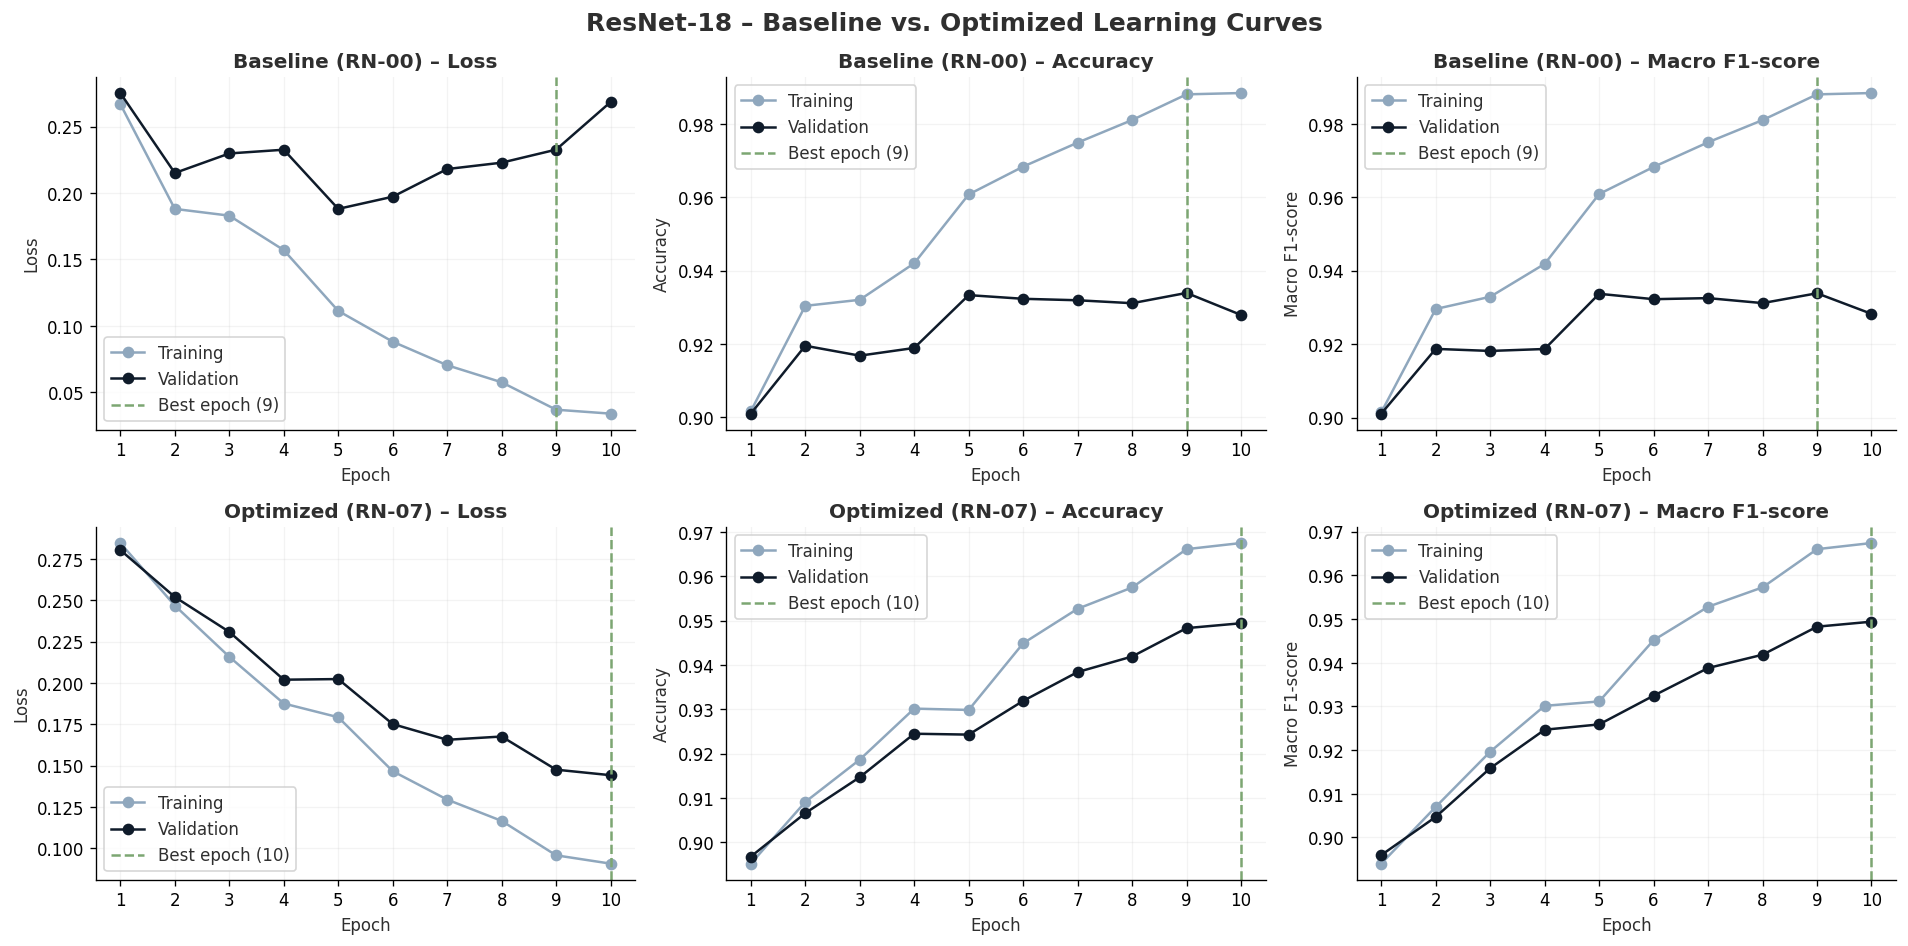

In [47]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

metrics = [
    ("loss", "Loss"),
    ("accuracy", "Accuracy"),
    ("macro_f1", "Macro F1-score"),
]

for row_idx, (run_id, variant) in enumerate(
    [
        ("RN-00", "Baseline"),
        (best_run_id, "Optimized"),
    ]
):
    history = epoch_history.loc[epoch_history["run_id"] == run_id].sort_values("epoch")

    best_epoch = int(
        experiment_results.loc[
            experiment_results["run_id"] == run_id,
            "best_epoch",
        ].iloc[0]
    )

    for col_idx, (metric, label) in enumerate(metrics):
        ax = axes[row_idx, col_idx]

        ax.plot(
            history["epoch"],
            history[f"train_{metric}"],
            color=PALETTE["blue_3"],
            marker="o",
            label="Training",
        )

        ax.plot(
            history["epoch"],
            history[f"val_{metric}"],
            color=PALETTE["blue_7"],
            marker="o",
            label="Validation",
        )

        ax.axvline(
            best_epoch,
            color=PALETTE["green_dark"],
            linestyle="--",
            label=f"Best epoch ({best_epoch})",
        )

        ax.set_title(f"{variant} ({run_id}) – {label}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(label)
        ax.set_xticks(history["epoch"])
        ax.legend()
        ax.grid(alpha=0.15)

fig.suptitle(
    "ResNet-18 – Baseline vs. Optimized Learning Curves",
    fontsize=15,
    fontweight="bold",
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "resnet18_learning_curves.png",
    bbox_inches="tight",
)

plt.show()

**Observations**

A baseline esetében az 5. epoch után növekvő validation loss
és tovább javuló training teljesítmény figyelhető meg,
ami túlilleszkedésre utal.

Az optimalizált konfiguráció kisebb train-validation gapet,
alacsonyabb validation losst és magasabb validációs pontosságot
eredményezett, ami kedvezőbb általánosítási képességre utal.

### 8.2. Confusion Matrix and Class Performance

A baseline és az optimalizált modell validációs predikcióinak
összehasonlítása confusion matrix és osztályonkénti precision,
recall, valamint F1-score alapján.

Az elemzés célja a nehezen elkülöníthető kategóriák azonosítása
és az optimalizálás osztályonkénti hatásának vizsgálata.

In [48]:
y_val = np.asarray([train_dataset[int(idx)][1] for idx in val_indices])

evaluation_results = {}

for run_id, experiment in [
    ("RN-00", baseline_experiment),
    (best_run_id, best_experiment),
]:
    predictions = predict_model(
        model=experiment["model"],
        loader=experiment["loaders"]["val"],
        device=DEVICE,
    )

    assert len(predictions) == len(y_val) == 10_000

    matrix = confusion_matrix(
        y_val,
        predictions,
        labels=np.arange(len(CLASS_NAMES)),
    )

    report = pd.DataFrame(
        classification_report(
            y_val,
            predictions,
            labels=np.arange(len(CLASS_NAMES)),
            target_names=CLASS_NAMES,
            output_dict=True,
            zero_division=0,
        )
    ).T

    evaluation_results[run_id] = {
        "predictions": predictions,
        "confusion_matrix": matrix,
        "classification_report": report,
    }

    print(f"OK: {run_id}")

baseline_report = evaluation_results["RN-00"]["classification_report"]
best_report = evaluation_results[best_run_id]["classification_report"]

OK: RN-00
OK: RN-07


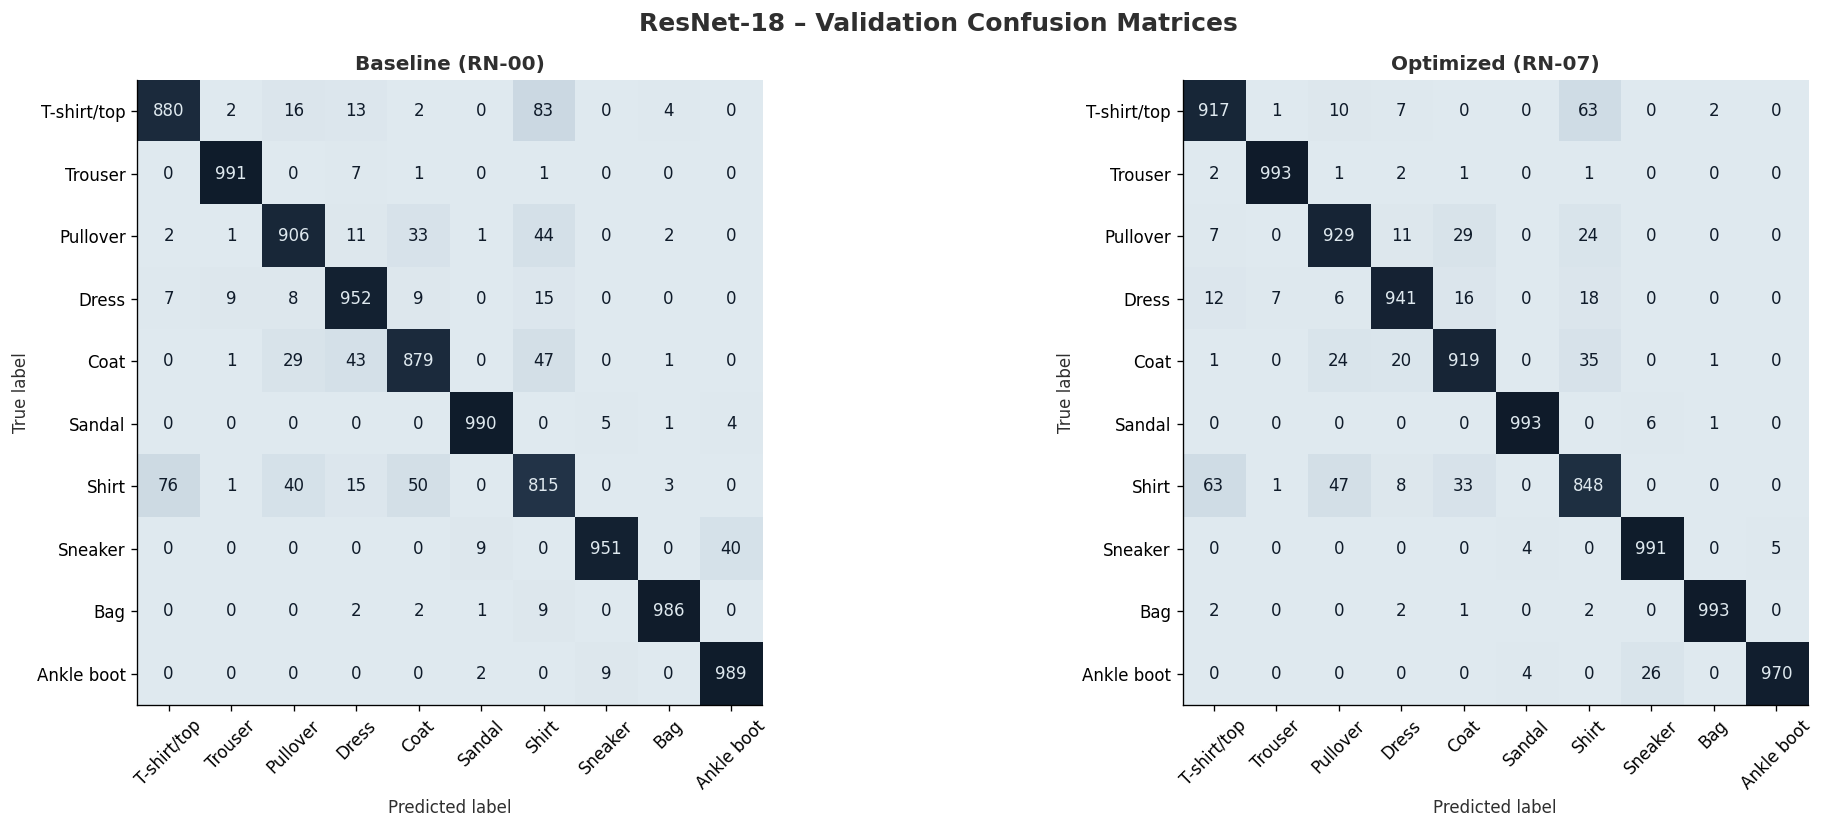

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, (run_id, variant) in zip(
    axes,
    [
        ("RN-00", "Baseline"),
        (best_run_id, "Optimized"),
    ],
):
    matrix = evaluation_results[run_id]["confusion_matrix"]

    display = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=CLASS_NAMES,
    )

    display.plot(
        ax=ax,
        cmap=BLUE_CMAP,
        colorbar=False,
        xticks_rotation=45,
        im_kw={"vmin": 0, "vmax": 1000},
    )

    ax.set_title(f"{variant} ({run_id})")

fig.suptitle(
    "ResNet-18 – Validation Confusion Matrices",
    fontsize=15,
    fontweight="bold",
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "resnet18_confusion_matrices.png",
    bbox_inches="tight",
)

plt.show()

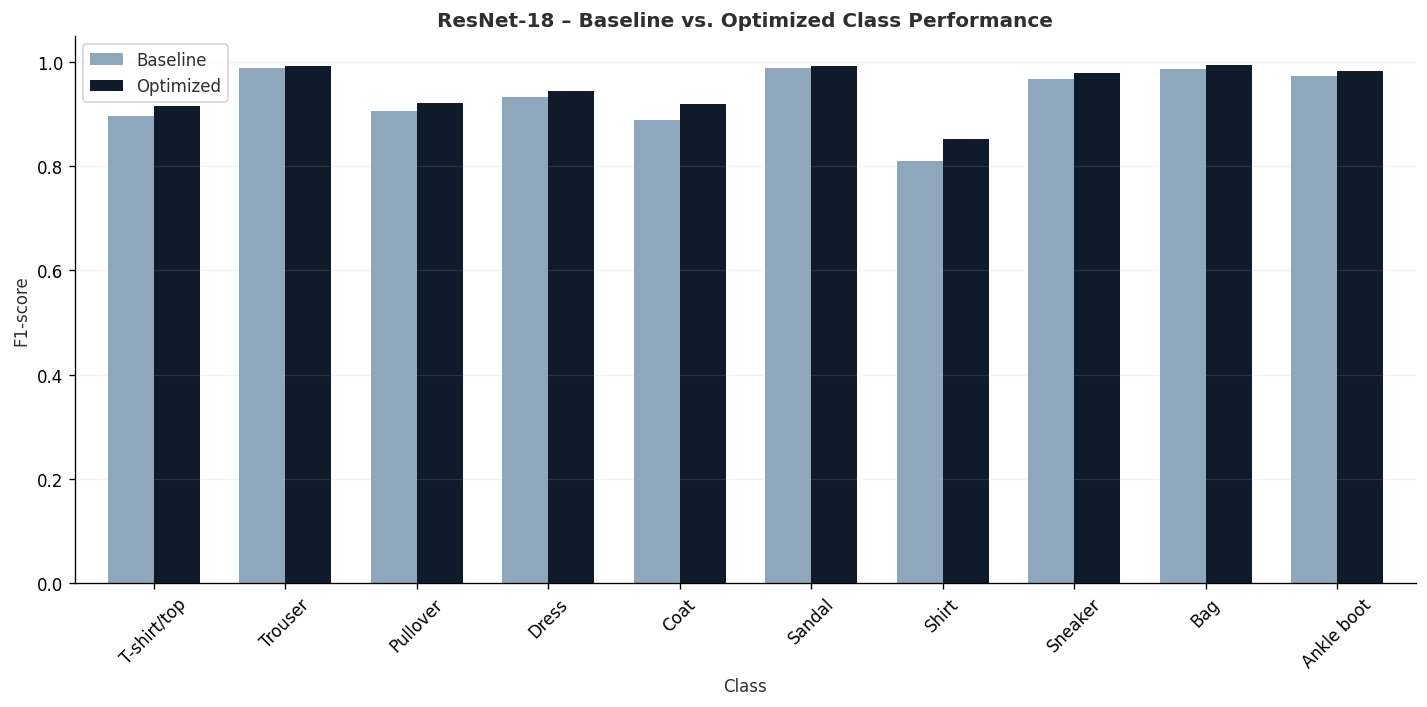

In [50]:
class_comparison = pd.DataFrame(
    {
        "Baseline": baseline_report.loc[CLASS_NAMES, "f1-score"],
        "Optimized": best_report.loc[CLASS_NAMES, "f1-score"],
    }
)

fig, ax = plt.subplots(figsize=(12, 6))

class_comparison.plot(
    kind="bar",
    ax=ax,
    color=[
        PALETTE["blue_3"],
        PALETTE["blue_7"],
    ],
    width=0.7,
    rot=45,
)

ax.set_ylim(0, 1.05)
ax.set_xlabel("Class")
ax.set_ylabel("F1-score")
ax.set_title("ResNet-18 – Baseline vs. Optimized Class Performance")
ax.grid(axis="y", alpha=0.15)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "resnet18_class_performance.png",
    bbox_inches="tight",
)

plt.show()

In [51]:
class_comparison["Difference (pp)"] = (
    class_comparison["Optimized"] - class_comparison["Baseline"]
) * 100

class_comparison.round(4)

,Baseline,Optimized,Difference (pp)
T-shirt/top,0.8957,0.9152,1.9495
Trouser,0.9885,0.9920,0.3479
Pullover,0.9065,0.9212,1.4717
Dress,0.9320,0.9453,1.3291
Coat,0.8897,0.9195,2.9784
Sandal,0.9885,0.9925,0.3987
Shirt,0.8093,0.8518,4.2499
Sneaker,0.9679,0.9797,1.1794
Bag,0.9875,0.9945,0.7011
Ankle boot,0.9729,0.9823,0.9332


**Observations**

Az optimalizált modell mind a tíz kategóriában magasabb
F1-score-t ért el. A legnagyobb javulás a Shirt (+4,25 pp),
Coat (+2,98 pp) és T-shirt/top (+1,95 pp) kategóriákban
figyelhető meg.

A Shirt továbbra is a legnehezebben osztályozható kategória,
azonban a helyesen osztályozott mintáinak száma 815-ről
848-ra nőtt. A fő tévesztési mintázatok összhangban állnak
a korábbi EDA során azonosított vizuális hasonlóságokkal.

### 8.3. Experiment Comparison

A kísérletek validációs pontosságának összehasonlítása
az RN-00 baseline konfigurációhoz viszonyítva.

A baseline és az optimalizált modell prediktív teljesítményét
és számítási költségeit összefoglaló táblázatban értékeljük.

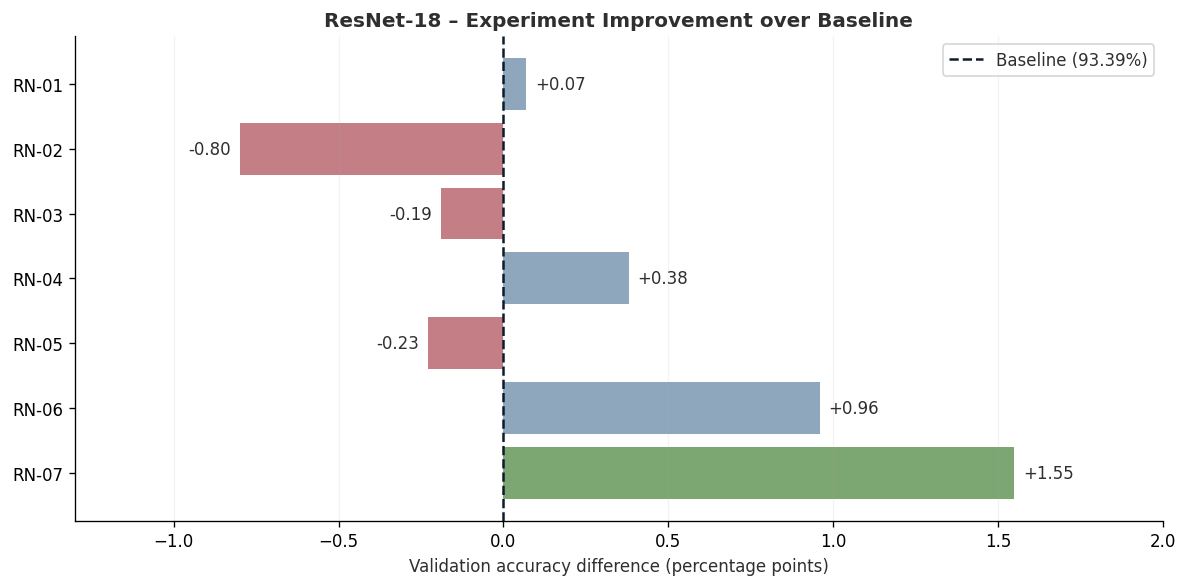

In [52]:
baseline_accuracy = baseline_result["val_accuracy"]

delta_results = (
    experiment_results.loc[experiment_results["run_id"] != "RN-00"].sort_values("run_id").copy()
)

delta_results["accuracy_delta_pp"] = (delta_results["val_accuracy"] - baseline_accuracy) * 100

colors = [
    PALETTE["green_dark"]
    if run_id == best_run_id
    else PALETTE["red_light"]
    if delta < 0
    else PALETTE["blue_3"]
    for run_id, delta in zip(
        delta_results["run_id"],
        delta_results["accuracy_delta_pp"],
    )
]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    delta_results["run_id"],
    delta_results["accuracy_delta_pp"],
    color=colors,
)

ax.bar_label(bars, fmt="%+.2f", padding=5)

ax.axvline(
    0,
    color=PALETTE["blue_7"],
    linestyle="--",
    label=f"Baseline ({baseline_accuracy:.2%})",
)

ax.invert_yaxis()
ax.set_xlim(-1.3, 2.0)
ax.set_xlabel("Validation accuracy difference (percentage points)")
ax.set_title("ResNet-18 – Experiment Improvement over Baseline")
ax.legend()
ax.grid(axis="x", alpha=0.15)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "resnet18_experiment_baseline_comparison.png",
    bbox_inches="tight",
)

plt.show()

In [53]:
comparison = (
    experiment_results.set_index("run_id")
    .loc[
        ["RN-00", best_run_id],
        [
            "best_epoch",
            "train_accuracy",
            "val_accuracy",
            "train_macro_f1",
            "val_macro_f1",
            "train_loss",
            "val_loss",
            "accuracy_gap",
            "preprocessing_time_s",
            "training_time_s",
            "inference_time_s",
            "forward_inference_time_s",
            "inference_time_per_sample_ms",
            "parameter_count",
            "model_size_mib",
        ],
    ]
    .T
)

comparison.columns = ["Baseline", "Optimized"]

comparison["Difference"] = comparison["Optimized"] - comparison["Baseline"]

comparison.round(6)

,Baseline,Optimized,Difference
best_epoch,9.000000e+00,1.000000e+01,1.000000
train_accuracy,9.880200e-01,9.674800e-01,-0.020540
val_accuracy,9.339000e-01,9.494000e-01,0.015500
train_macro_f1,9.880060e-01,9.673880e-01,-0.020618
val_macro_f1,9.338510e-01,9.493900e-01,0.015539
train_loss,3.683700e-02,9.078300e-02,0.053945
val_loss,2.326700e-01,1.442210e-01,-0.088449
accuracy_gap,5.412000e-02,1.808000e-02,-0.036040
preprocessing_time_s,1.430100e-02,1.426400e-02,-0.000037
training_time_s,6.433385e+02,6.258521e+02,-17.486354


**Observations**

Az egyedi optimalizálások közül a CosineAnnealingLR
eredményezte a legnagyobb validációs pontosságjavulást
(+0,96 pp), míg az augmentáció biztosította a legkisebb
train-validation gapet.

A kombinált RN-07 konfiguráció 1,55 százalékpontos
pontosságjavulást ért el a baseline-hoz képest,
változatlan tanítható paraméterszám mellett.

A futásidők összehasonlíthatósága korlátozott, mivel
a kísérletek két különböző Colab munkamenetben készültek.

### 8.4. Residual Feature Map Visualization

A baseline és az optimalizált modell négy reziduális
szakaszának aktivációvizualizációja azonos validációs mintán.

Az elemzés célja a különböző hálózati mélységekben
megtanult képi reprezentációk kvalitatív szemléltetése.

In [54]:
@torch.no_grad()
def extract_feature_maps(model, image):
    """Extract activations from the four residual stages."""
    model.eval()

    x = image.to(DEVICE)

    x = model.conv1(x)
    x = model.bn1(x)
    x = model.relu(x)
    x = model.maxpool(x)

    feature_maps = {}

    for name in ["layer1", "layer2", "layer3", "layer4"]:
        x = getattr(model, name)(x)
        feature_maps[name] = x[0].detach().cpu()

    return feature_maps

In [55]:
SAMPLE_INDEX = 0

original_image, sample_label = train_dataset[int(val_indices[SAMPLE_INDEX])]

baseline_image, _ = baseline_experiment["loaders"]["val"].dataset[SAMPLE_INDEX]

optimized_image, _ = best_experiment["loaders"]["val"].dataset[SAMPLE_INDEX]

baseline_maps = extract_feature_maps(
    baseline_experiment["model"],
    baseline_image.unsqueeze(0),
)

optimized_maps = extract_feature_maps(
    best_experiment["model"],
    optimized_image.unsqueeze(0),
)

print("Validation sample:", SAMPLE_INDEX)
print("Actual class:", CLASS_NAMES[sample_label])

for name, feature_map in baseline_maps.items():
    print(name, tuple(feature_map.shape))

Validation sample: 0
Actual class: T-shirt/top
layer1 (64, 28, 28)
layer2 (128, 14, 14)
layer3 (256, 7, 7)
layer4 (512, 4, 4)


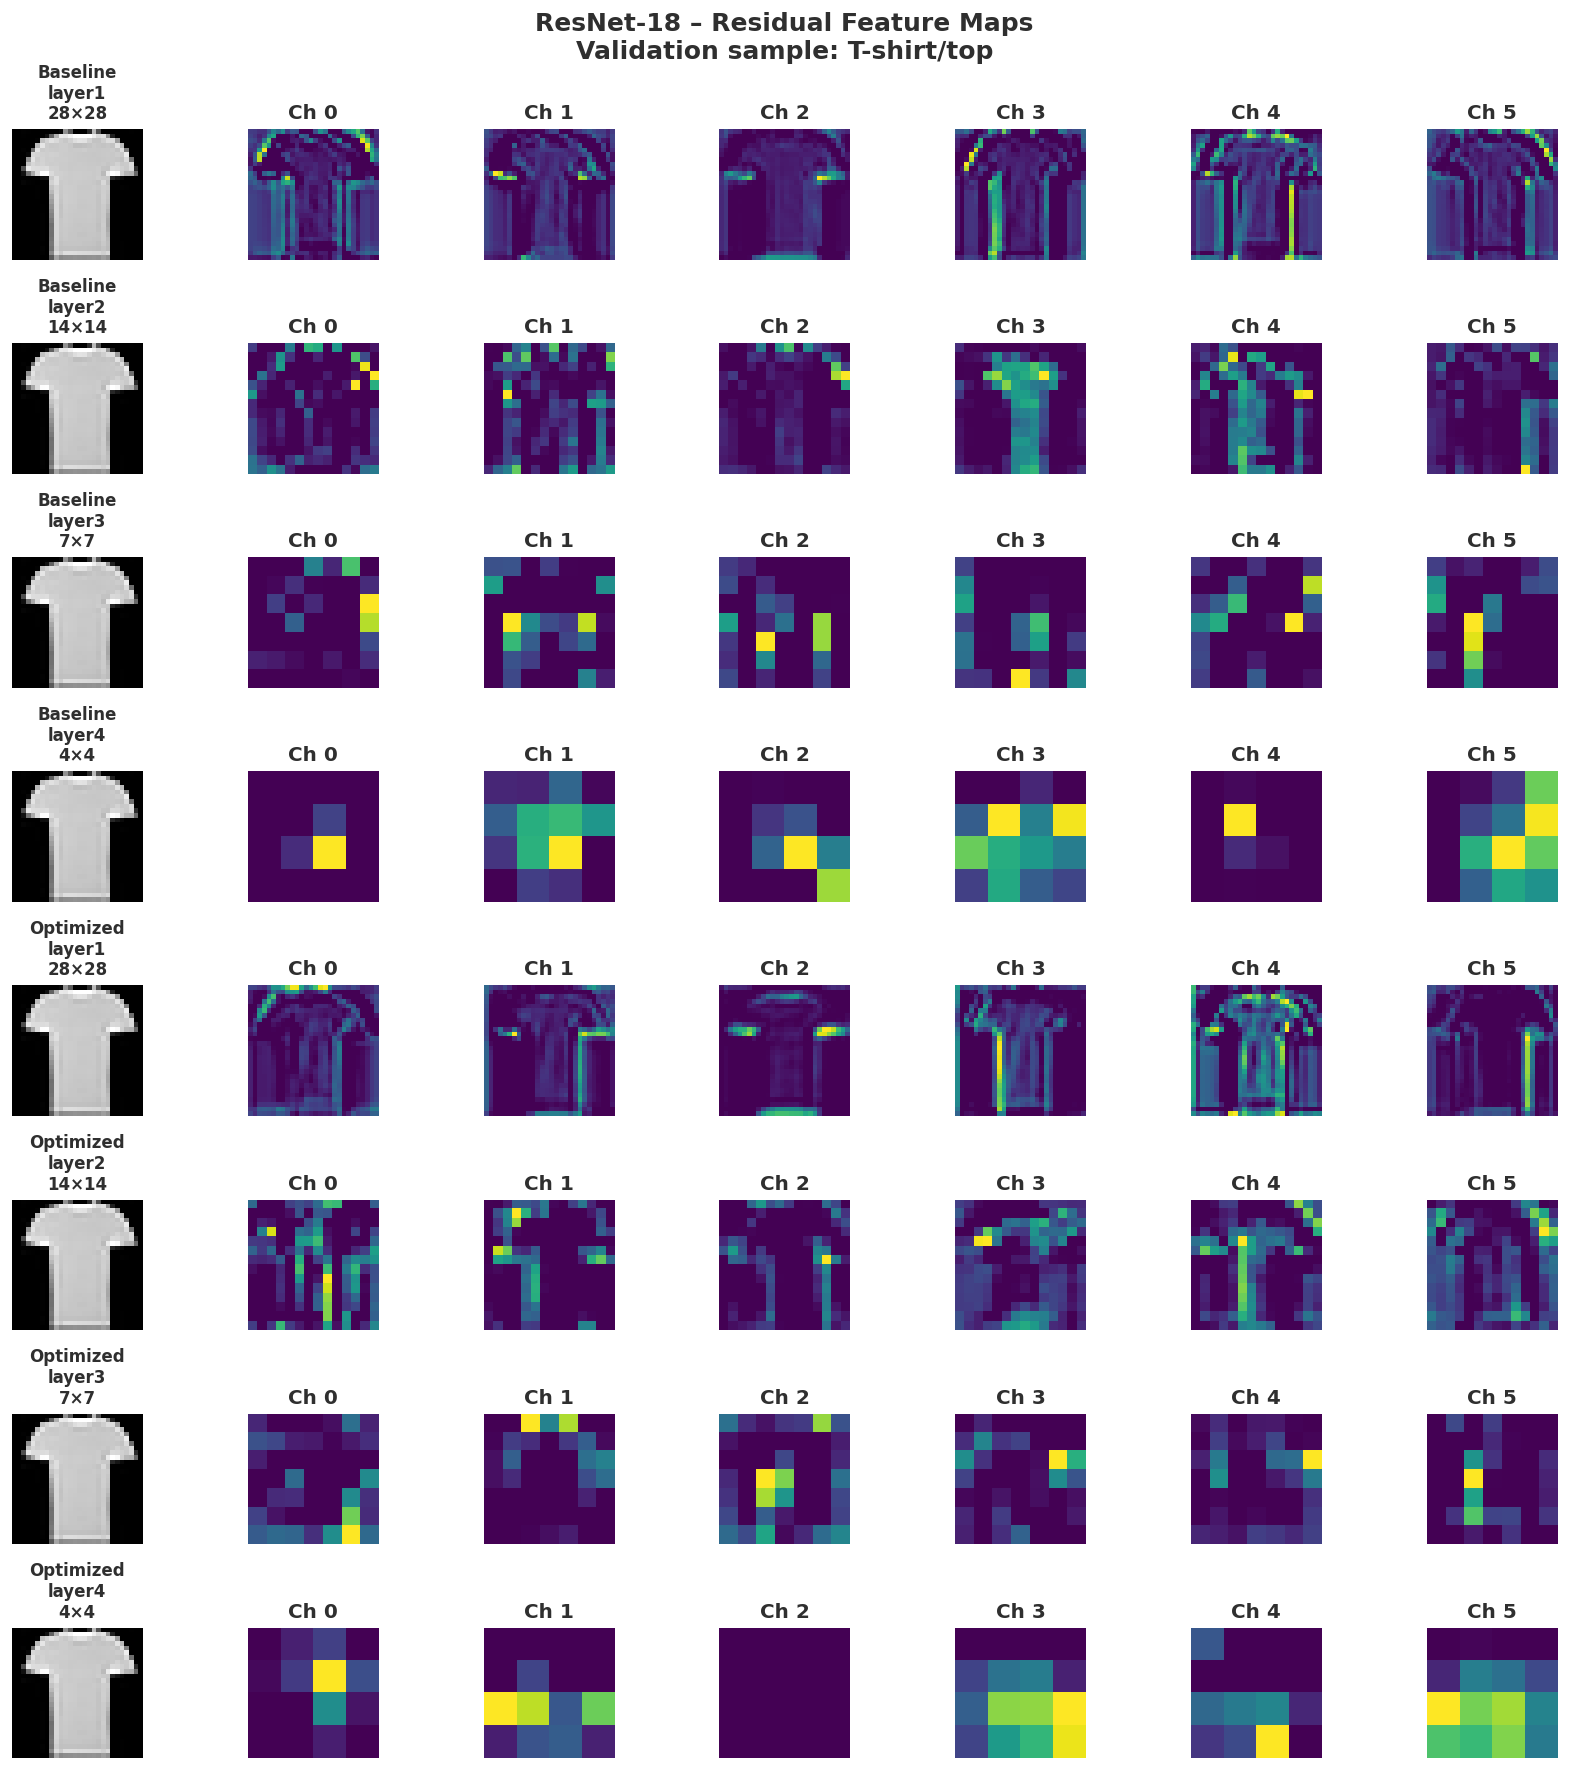

In [56]:
N_CHANNELS = 6

fig, axes = plt.subplots(
    8,
    N_CHANNELS + 1,
    figsize=(14, 15),
)

for model_idx, (variant, maps) in enumerate(
    [
        ("Baseline", baseline_maps),
        ("Optimized", optimized_maps),
    ]
):
    for layer_idx, (name, feature_map) in enumerate(maps.items()):
        row_idx = model_idx * 4 + layer_idx

        axes[row_idx, 0].imshow(
            original_image,
            cmap="gray",
        )

        axes[row_idx, 0].set_title(
            f"{variant}\n{name}\n{feature_map.shape[1]}×{feature_map.shape[2]}",
            fontsize=10,
        )

        axes[row_idx, 0].axis("off")

        for channel in range(N_CHANNELS):
            ax = axes[row_idx, channel + 1]

            ax.imshow(
                feature_map[channel],
                cmap="viridis",
                interpolation="nearest",
            )

            ax.set_title(f"Ch {channel}")
            ax.axis("off")

fig.suptitle(
    f"ResNet-18 – Residual Feature Maps\nValidation sample: {CLASS_NAMES[sample_label]}",
    fontsize=15,
    fontweight="bold",
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "resnet18_feature_maps.png",
    bbox_inches="tight",
)

plt.show()

**Observations**

A korai reziduális szakaszok aktivációiban felismerhetők
a ruhadarab körvonalai és lokális élei. A mélyebb szakaszokban
a térbeli felbontás 28×28-ról 4×4-re csökken, és kompaktabb
képi reprezentációk jelennek meg.

A baseline és az optimalizált modell eltérő aktivációs
mintázatokat tanult. A vizualizáció kvalitatív jellegű,
az egyes csatornák intenzitása közvetlenül nem összehasonlítható.

## 9. Final Results Export

A baseline és az optimalizált modell összesített metrikáinak
és osztályonkénti validációs eredményeinek exportálása
a közös modellösszehasonlításhoz.

A hivatalos teszthalmaz értékelése a projekt végső
összehasonlítási szakaszában történik.

In [57]:
final_metrics = experiment_results.set_index("run_id").loc[["RN-00", best_run_id]].reset_index()

final_metrics.insert(
    1,
    "model_variant",
    ["baseline", "optimized"],
)

for row_idx, report in enumerate([baseline_report, best_report]):
    final_metrics.loc[row_idx, "val_macro_precision"] = report.loc["macro avg", "precision"]
    final_metrics.loc[row_idx, "val_macro_recall"] = report.loc["macro avg", "recall"]

final_metrics.to_csv(
    FINAL_METRICS_PATH,
    index=False,
)

print(f"Final metrics saved: {FINAL_METRICS_PATH.name}")

final_metrics[
    [
        "run_id",
        "model_variant",
        "train_accuracy",
        "val_accuracy",
        "val_macro_precision",
        "val_macro_recall",
        "val_macro_f1",
        "val_loss",
        "training_time_s",
        "model_size_mib",
    ]
].round(6)

Final metrics saved: resnet18_final_metrics.csv


,run_id,model_variant,train_accuracy,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_loss,training_time_s,model_size_mib
0,RN-00,baseline,0.98802,0.9339,0.934091,0.9339,0.933851,0.232670,643.338480,42.686473
1,RN-07,optimized,0.96748,0.9494,0.949459,0.9494,0.949390,0.144221,625.852126,42.686534


In [58]:
classification_results = []

for variant, run_id, report in [
    ("baseline", "RN-00", baseline_report),
    ("optimized", best_run_id, best_report),
]:
    class_report = report.loc[CLASS_NAMES].copy()

    class_report.index.name = "class"
    class_report = class_report.reset_index()

    class_report.insert(0, "run_id", run_id)
    class_report.insert(1, "model_variant", variant)
    class_report.insert(2, "split", "validation")

    classification_results.append(class_report)

classification_results = pd.concat(
    classification_results,
    ignore_index=True,
)

classification_results.to_csv(
    CLASSIFICATION_REPORT_PATH,
    index=False,
)

print(f"Classification report saved: {CLASSIFICATION_REPORT_PATH.name}")

classification_results.round(6)

Classification report saved: resnet18_classification_report.csv


,run_id,model_variant,split,class,precision,recall,f1-score,support
0,RN-00,baseline,validation,T-shirt/top,0.911917,0.880,0.895674,1000.0
1,RN-00,baseline,validation,Trouser,0.986070,0.991,0.988529,1000.0
2,RN-00,baseline,validation,Pullover,0.906907,0.906,0.906453,1000.0
3,RN-00,baseline,validation,Dress,0.912752,0.952,0.931963,1000.0
4,RN-00,baseline,validation,Coat,0.900615,0.879,0.889676,1000.0
5,RN-00,baseline,validation,Sandal,0.987039,0.990,0.988517,1000.0
6,RN-00,baseline,validation,Shirt,0.803748,0.815,0.809335,1000.0
7,RN-00,baseline,validation,Sneaker,0.985492,0.951,0.967939,1000.0
8,RN-00,baseline,validation,Bag,0.988967,0.986,0.987481,1000.0
9,RN-00,baseline,validation,Ankle boot,0.957406,0.989,0.972946,1000.0


In [59]:
expected_files = {
    RESULTS_PATH: 8,
    EPOCH_HISTORY_PATH: 80,
    FINAL_METRICS_PATH: 2,
    CLASSIFICATION_REPORT_PATH: 20,
}

for path, expected_rows in expected_files.items():
    assert path.is_file(), f"Missing file: {path.name}"

    row_count = len(pd.read_csv(path))
    assert row_count == expected_rows

    print(f"OK: {path.name} – {row_count} rows")

print("\nSaved figures:")

for path in sorted(FIGURES_DIR.glob("*.png")):
    print(f"OK: {path.name}")

OK: resnet18_experiments.csv – 8 rows
OK: resnet18_epoch_history.csv – 80 rows
OK: resnet18_final_metrics.csv – 2 rows
OK: resnet18_classification_report.csv – 20 rows

Saved figures:
OK: resnet18_class_performance.png
OK: resnet18_confusion_matrices.png
OK: resnet18_experiment_baseline_comparison.png
OK: resnet18_feature_maps.png
OK: resnet18_learning_curves.png


## 10. Conclusions

A nyolc dokumentált kísérlet közül az RN-07 kombinált
konfiguráció biztosította a legjobb validációs teljesítményt.

A főbb megállapítások:

- A ResNet-18 baseline modellje már önmagában meghaladta
  a Simple CNN optimalizált modelljének validációs pontosságát.
- Az egyedi optimalizálások közül a CosineAnnealingLR
  eredményezte a legnagyobb pontosságjavulást.
- A RandomAffine augmentáció biztosította a legkisebb
  train-validation gapet.
- A dropout, augmentáció és scheduler kombinációja 93,39%-ról
  94,94%-ra növelte a validációs pontosságot, változatlan
  tanítható paraméterszám mellett.
- Az optimalizált modell mind a tíz kategóriában javította
  az F1-score-t.
- A Shirt továbbra is a legnehezebben osztályozható kategória.

A korlátozott GPU-kapacitás és tanítási idő miatt az opcionális
RN-08 és RN-09 kísérleteket elhagytuk.

Az eredmények egyetlen adatfelosztás és random seed alapján
születtek. A különböző futtatási környezetek és Colab
munkamenetek korlátozzák a futásidők összehasonlíthatóságát.

A baseline és optimalizált modell checkpointjai rendelkezésre
állnak a projekt végső test-set értékeléséhez.

## 11. Final Backup

A modell-checkpointok, kísérleti eredmények és vizualizációk
exportálása a lokális repositoryba történő visszaállításhoz.

In [60]:
final_zip_path = OUTPUT_ROOT / "resnet18_final_backup.zip"

files_to_export = [
    *ARTIFACTS_DIR.rglob("*"),
    *RESULTS_DIR.glob("resnet18_*.csv"),
    *FIGURES_DIR.glob("*.png"),
]

with ZipFile(
    final_zip_path,
    "w",
    compression=ZIP_DEFLATED,
) as archive:
    for path in files_to_export:
        if path.is_file():
            archive.write(
                path,
                arcname=path.relative_to(OUTPUT_ROOT),
            )

print(f"Backup created: {final_zip_path.name}")
print(f"Size: {final_zip_path.stat().st_size / 1024**2:.2f} MiB")

with ZipFile(final_zip_path) as archive:
    assert archive.testzip() is None

    print("\nExported files:")
    for filename in archive.namelist():
        print(filename)

Backup created: resnet18_final_backup.zip
Size: 318.40 MiB

Exported files:
artifacts/resnet18/RN-01/config.json
artifacts/resnet18/RN-01/model.pt
artifacts/resnet18/RN-00/config.json
artifacts/resnet18/RN-00/model.pt
artifacts/resnet18/RN-03/config.json
artifacts/resnet18/RN-03/model.pt
artifacts/resnet18/RN-06/config.json
artifacts/resnet18/RN-06/model.pt
artifacts/resnet18/RN-02/config.json
artifacts/resnet18/RN-02/model.pt
artifacts/resnet18/RN-04/config.json
artifacts/resnet18/RN-04/model.pt
artifacts/resnet18/RN-05/config.json
artifacts/resnet18/RN-05/model.pt
artifacts/resnet18/RN-07/config.json
artifacts/resnet18/RN-07/model.pt
results/experiments/resnet18_classification_report.csv
results/experiments/resnet18_final_metrics.csv
results/experiments/resnet18_experiments.csv
results/experiments/resnet18_epoch_history.csv
results/figures/resnet18/resnet18_confusion_matrices.png
results/figures/resnet18/resnet18_experiment_baseline_comparison.png
results/figures/resnet18/resnet18_cl

In [61]:
if IN_COLAB:
    from google.colab import files

    files.download(str(final_zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>